**Pump with Performance Curves: Water at 15 m³/h**

In this tutorial we model a centrifugal water pump whose head and efficiency follow its **performance curves**, and validate the result against DWSIM's Pump in *Curves* calculation mode (Steam Tables property package).

### Pump curves (impeller 200 mm, 1450 rpm):

| Flow (m³/h) | 0 | 3 | 6 | 9 | 12 | 13.5 | 15 | 16.5 | 18 | 19.5 |
|---|---|---|---|---|---|---|---|---|---|---|
| Head (m) | 44.53 | 44.15 | 43.78 | 42.67 | 40.82 | 38.96 | 37.11 | 35.25 | 32.65 | 29.68 |
| Efficiency (%) | 0 | 30 | 48.8 | 63.8 | 71.3 | 73.5 | 75 | 73.5 | 71.3 | 67.5 |
| NPSH required (m) | 0.51 | 0.51 | 0.56 | 0.68 | 0.84 | 0.96 | 1.13 | 1.35 | 1.69 | 2.03 |

### Inlet specifications:

* **Fluid**: water, 4.155 kg/s (15 m³/h)
* **Temperature**: 298.15 K
* **Pressure**: 2.882 bar

### Pump equations:

$$\Delta P = \rho\, g\, H(Q) \qquad W_{fluid} = Q\,\Delta P \qquad W_{shaft} = \frac{W_{fluid}}{\eta(Q)} \qquad NPSH_a = \frac{P_{in} - P_{sat}(T_{in})}{\rho\, g}$$

---

> **Curves as smooth piecewise linear functions**
>
> DWSIM interpolates linearly between the curve points. `pump_curves.py` writes the same linear interpolation as one expression that is valid at any flow,
> $$y(Q) = y_0 + s_0 (Q - Q_0) + \sum_k (s_k - s_{k-1}) \max(0, Q - Q_k)$$
> where $s_k$ is the slope of segment $k$ and each max is smoothed with IDAES's `smooth_max`. Because the expression does not depend on which segment the flow is in, the solver can move freely along the curve, for example when the flow is not fixed but set by a system curve.

> **Where the efficiency losses go**
>
> IDAES's `Pump` adds the full shaft work to the fluid, so the 25 % efficiency losses heat the water (ΔT ≈ 0.036 K). DWSIM adds only the hydraulic work $Q\,\Delta P$ to the fluid (ΔT ≈ 0.007 K) and treats the losses as leaving the system. Head, pressure, power and NPSH are unaffected; only this tiny temperature rise differs.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


## Setting up and solving the flowsheet

The flowsheet is Feed → Pump → Product, built in `pump_curves.py`. The inlet is fixed; the curves set the pressure rise and the efficiency.

In [2]:
from pump_curves import setup_pump_curve_model, report_pump_properties

# Create and solve the model
model, results = setup_pump_curve_model(
    flow_mass=4.1547394372007966,  # kg/s (15 m3/h)
    temperature=298.15199942972197,  # K
    pressure=288159.28901000967,  # Pa
)
print(results.solver.termination_condition)

prop = report_pump_properties(model)

The initial DOF is 5
The final DOF is 0
optimal

Unit : fs.feed                                                             Time: 0.0
------------------------------------------------------------------------------------
    Stream Table
                         Units          Outlet  
    Molar Flow          mole / second     230.62
    Mass Flow       kilogram / second     4.1547
    T                          kelvin     298.15
    P                          pascal 2.8816e+05
    Vapor Fraction      dimensionless     0.0000
    Molar Enthalpy       joule / mole     1893.4

Unit : fs.pump                                                             Time: 0.0
------------------------------------------------------------------------------------
    Unit Performance

    Variables: 

    Key             : Value      : Units         : Fixed : Bounds
    Mechanical Work :     2016.1 :          watt : False : (None, None)
    Pressure Change : 3.6295e+05 :        pascal : False : (None, None)
 

## Pump curves and operating point

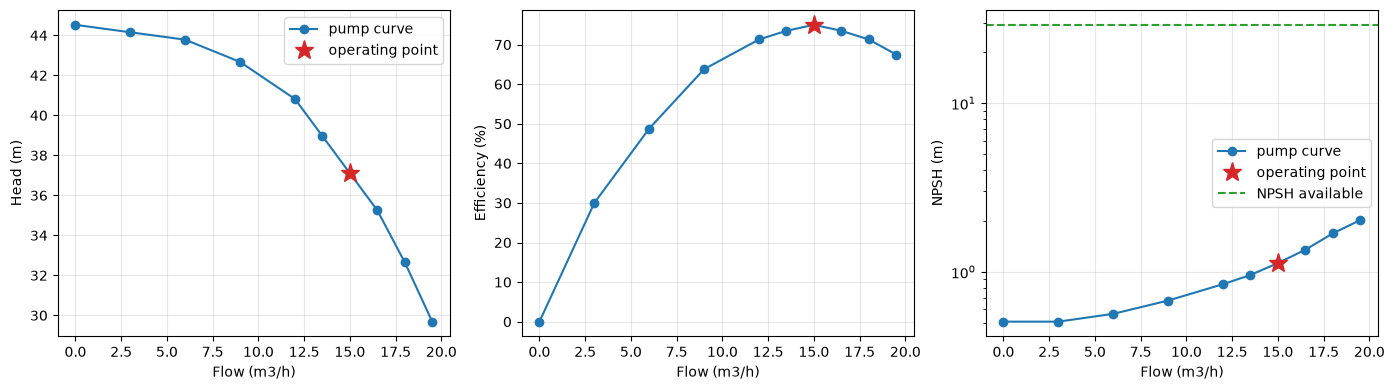

NPSH margin: 29.1 m available vs 1.13 m required


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pump_curves import FLOW_POINTS, CURVES, pump_results

res = pump_results(model)
q = res["Volumetric flow (m3/h)"]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
for ax, key, label, value_key in (
    (ax1, "head", "Head (m)", "Head (m)"),
    (ax2, "efficiency", "Efficiency (%)", "Efficiency (%)"),
    (ax3, "npsh_required", "NPSH (m)", "NPSH required (m)"),
):
    ax.plot(FLOW_POINTS, CURVES[key], "o-", color="tab:blue", label="pump curve")
    ax.plot(q, res[value_key], "*", color="tab:red", markersize=14, label="operating point")
    ax.set_xlabel("Flow (m3/h)")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
ax3.axhline(res["NPSH available (m)"], color="tab:green", linestyle="--", label="NPSH available")
ax3.set_yscale("log")
ax1.legend()
ax3.legend()
plt.tight_layout()
plt.show()

print("NPSH margin: {0:.1f} m available vs {1:.2f} m required".format(res["NPSH available (m)"], res["NPSH required (m)"]))

In [4]:
# Visualize (if needed)
model.fs.visualize("Pump Curves Model")

'idaes.co re.util.diagnostics_tools.diagnostics_toolbox.DiagnosticsToolbox'.
Please update your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
'idaes.core.util.diagnostics_tools.diagnostics_toolbox.CONFIG'. Please update
your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
2026-11-09 14:58:04 [INFO] idaes.idaes_ui.fv.fsvis: Started visualization server
2026-11-09 14:58:04 [INFO] idaes.idaes_ui.fv.fsvis: Saving flowsheet to default file 'Pump Curves Model.json' in current directory (c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\Pump Curves DWSim)
2026-11-09 14:58:04 [WARNING] idaes.idaes_ui.fv.fsvis: Flowsheet name changed: old='Pump Curves Model' new='Pump-Curves-Model'
Flowsheet name changed to 'Pump-Curves-Model'
2026-11-09 14:58:04 [INFO] idaes.idaes_ui.fv.fsvis: Flowsheet visualization at: http://localhost:55803/app?id=Pump-Curves-Model


VisualizeResult(store=<idaes_ui.fv.persist.FileDataStore object at 0x000001B466480830>, port=55803, server=<idaes_ui.fv.model_server.FlowsheetServer object at 0x000001B42FC53CE0>, save_diagram=<bound method SaveDiagramScreenshot.save_diagram_screenshot of <idaes_ui.fv.save_diagram_screenshot.SaveDiagramScreenshot object at 0x000001B46633FC50>>)

## Validation against DWSIM

The DWSIM results are read directly from the solved `.dwxmz` file and compared with IDAES. Everything agrees to within 0.02 % except the temperature rise, which follows from the different treatment of the efficiency losses explained above; the hydraulic power, which is the enthalpy DWSIM adds to the fluid, agrees.

In [5]:
from pump_curves import read_dwsim_results, compare_with_dwsim

dwsim = read_dwsim_results("DWSim Pump Curves Model.dwxmz")
compare_with_dwsim(model, dwsim)

,IDAES,DWSIM,Difference,Error (%)
Volumetric flow (m3/h),15.000081,15.000088,-6.520647e-06,-4.347072e-05
Head (m),37.104899,37.104899,3.491632e-07,9.410163e-07
Efficiency (%),74.999919,74.999963,-4.425262e-05,-5.900352e-05
Pressure increase (bar),3.629549,3.629550,-8.057017e-07,-2.219839e-05
Outlet pressure (bar),6.511142,6.511143,-8.057017e-07,-1.237420e-05
Power (kW),2.016117,2.016429,-3.123557e-04,-1.549054e-02
Hydraulic power (kW),1.512086,1.512322,-2.354628e-04,-1.556962e-02
Temperature rise (K),0.035709,0.006688,2.902149e-02,4.339374e+02
NPSH available (m),29.134440,29.134452,-1.191749e-05,-4.090516e-05
NPSH required (m),1.126012,1.126011,1.074888e-06,9.545980e-05
